# 08A — Football outcome feasibility

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author.

**Question.** Which football-specific outcomes of an NFL player-play are actually *observable* in the delivered data — for which positions, on how many athletes and games, with which selection or leakage problem — and which are unsupported?

| Section | Brief | Output |
|---|---|---|
| 1 | candidate declarations and source fields | `football_field_audit` |
| 2 | athlete coverage, game exposure, opportunity | `football_outcome_coverage`, figure `AM08A_01` |
| 3 | when is a candidate recorded (selection / leakage) | `football_outcome_conditions` |
| 4 | reliability feasibility (odd / even games) | `football_outcome_split_half` |
| 5 | tracking event inventory (full mode, optional) | `tracking_event_inventory` |
| 6 | feasibility registry, gate 08A, reading | `football_outcome_feasibility_registry`, figure `AM08A_02`, manifest |

**Rules.** Candidates are declared in `scouting_feasibility.CANDIDATES` before any value is read. Nothing is labelled that the vendor did not record: a null is never read as 0, an outcome that needs a pairing of athletes is *unsupported*, a missing field stays missing. The status rule reads declarations and counts only. No Combine value is read; no association of a candidate with anything is computed. Vendor definitions are **inferred from column names** (no data dictionary in the repository).

**If no candidate is defensible, the football-outcome branch stops here** — that is a result, not a failure.

**Prerequisite.** Notebooks 05A and 05B executed in the same `RUN_MODE`. No PyTorch. Outputs: `…/advanced_movement/scouting_v1/` (smoke: `…/_sample/scouting_v1/`).

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'            # 'smoke' | 'full' — must match notebooks 05A / 05B
SEED = 20261011
FORCE_REBUILD = False         # True = recompute a stage even when its cached tables are current
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '08A.1'  # part of every cache key and provenance record
BOOTSTRAP_ITERATIONS = 1000   # athlete bootstrap of the split-half (smoke mode uses 100)
NUM_WORKERS = 0               # kept for interface parity: this notebook is single-process

AUDIT_TRACKING_EVENTS = True  # section 5: one column scan of silver.game_tracking (skipped in smoke mode)

## 0. Setup, inputs, synthetic validation

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import json
import time
from dataclasses import replace

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.tables import LayerRefs
from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import scouting_feasibility as sf
from nflbdb.research.advanced_movement import scouting_validation as sv
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement.artifacts import ScoutingStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
fc = sf.FeasibilityConfig().for_mode(controls)
if not controls.smoke:
    fc = replace(fc, n_boot=BOOTSTRAP_ITERATIONS)
store = ScoutingStore(cfg, controls)
refs = LayerRefs(cfg)
amc.seed_everything(controls.seed)
NB = {'05A': '05a_nfl_movement_outcome_eda.ipynb', '05B': '05b_nfl_outcome_reliability_and_freeze.ipynb'}

# ---- the frozen Milestone 05 registry gives the outcome configuration of the 05A play table: read, verified, never written
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
_, ocfg = tr.frozen_targets(registry_doc)
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
PLAYS_FILE = store.nfl.parquet(no.plays_contract(ocfg))

# ---- vendor definition of get-off: read from the project file, never assumed
_getoff = cfg.paths.project_root / 'configs' / 'player_get_off_definition.json'
GETOFF_STATUS = json.loads(_getoff.read_text(encoding='utf-8')).get('status', 'unresolved') if _getoff.is_file() else 'unresolved'
DEFINITION_OVERRIDES = {'FO05.player_get_off': GETOFF_STATUS}
PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'feasibility': fc.params(), 'candidates': sf.registry_hash(),
          'definition_overrides': DEFINITION_OVERRIDES}

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {plays.height:,} tracked player-plays · {int(plays["eligible"].sum()):,} eligible · '
                 f'{plays["nfl_id"].n_unique()} athletes · {plays["game_id"].n_unique()} games · {len(sf.CANDIDATES)} candidates '
                 f'(declarations `{sf.registry_hash()}`) · get-off definition: `{GETOFF_STATUS}`'))
display(store.describe())

**Run mode: `full`** (FULL) · 251,089 tracked player-plays · 242,043 eligible · 401 athletes · 815 games · 16 candidates (declarations `51736e0157a92f18`) · get-off definition: `unresolved`

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


In [3]:
# ---- synthetic validation (planted, known answers; no project data). A failure stops the notebook.
validation = sv.run_all(sv.CHECKS_08A)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1):
    display(validation)
sv.assert_all_passed(validation)

check,status,detail
str,str,str
"""candidate_registry_contract""","""PASS""","""16 candidates: unique identifiers, complete declarations, hash follows the declarations"""
"""flag_and_null_parsing""","""PASS""","""recognised flag tokens only; null, NaN, empty and unknown tokens stay unobserved (never 0)"""
"""coverage_counts""","""PASS""","""athletes, eligible plays, observations, athlete-games and opportunity rate match the planted counts (ALL / position / DECLARED)"""
"""split_half_reliability""","""PASS""","""planted reliability recovered (r 0.851 vs 0.857); position offsets do not inflate it; no-trait r -0.008; no estimate below 3 athletes"""
"""status_rule_and_gate""","""PASS""","""ordered status rule, missing fields never created, gate PASS with branch continue / stop_branch, incomplete registry FAIL"""
"""no_combine_leak_and_events""","""PASS""","""Combine-named columns are refused; the event inventory counts frames and reports an absent column"""


## 1. Candidate declarations and source fields

The declarations are static (written before reading a value). The audit then says which required fields exist, how often they are filled among the tracked player-plays of notebook 05A, and what their values look like — **check the example values of every flag here**: only the tokens `true / t / 1 / y / yes` and `false / f / 0 / n / no` are read; anything else stays unobserved.

In [4]:
SCHEMAS = sf.source_schemas(refs)
with pl.Config(fmt_str_lengths=160, tbl_rows=-1, tbl_width_chars=260):
    display(sf.candidate_table().select('outcome_id', 'label', 'role', 'kind', 'positions', 'required_fields', 'interpretability',
                                        'leakage_risk', 'outcome_conditioned', 'needs_assignment', 'definition_status'))


def _build():
    t0 = time.perf_counter()
    base = sf.observation_base(plays, refs.scan('silver', 'player_play'))
    print(f'observation base: {base.height:,} player-plays × {base.width} columns ({time.perf_counter() - t0:.0f} s)')
    out = sf.run_audit(base, SCHEMAS, sf.CANDIDATES, fc, DEFINITION_OVERRIDES)
    print(f'audit tables built ({time.perf_counter() - t0:.0f} s)')
    return out


out = store.build('08a_feasibility', sf.CONTRACTS, _build, params=PARAMS, files=[PLAYS_FILE, *refs.files('silver', 'player_play')])
fields, coverage, conditions = out[sf.FIELD_AUDIT.name], out[sf.COVERAGE.name], out[sf.CONDITIONS.name]
reliability, registry = out[sf.RELIABILITY.name], out[sf.REGISTRY.name]
with pl.Config(fmt_str_lengths=160, tbl_rows=-1, tbl_width_chars=260):
    display(fields)

outcome_id,label,role,kind,positions,required_fields,interpretability,leakage_risk,outcome_conditioned,needs_assignment,definition_status
str,str,str,str,str,str,str,str,bool,bool,str
"""FO01.separation_at_pass_forward""","""Receiver separation when the pass is released""","""candidate""","""continuous""","""WR · TE""","""separation_at_pass_forward · route_ran""","""interaction_outcome""","""medium""",false,false,"""inferred_from_column_name"""
"""FO02.yards_after_catch""","""Yards after catch""","""candidate""","""continuous""","""WR · TE""","""yards_after_catch · target""","""interaction_outcome""","""high""",true,false,"""inferred_from_column_name"""
"""FO03.cushion""","""Pre-snap cushion""","""context""","""continuous""","""WR · TE · DB""","""cushion""","""context""","""low""",false,false,"""inferred_from_column_name"""
"""FO04.route_ran""","""Route label (conditioning of tracked movement)""","""context""","""category""","""WR · TE""","""route_ran""","""context""","""low""",false,false,"""inferred_from_column_name"""
"""FO05.player_get_off""","""Get-off""","""candidate""","""continuous""","""DL""","""player_get_off""","""movement""","""medium""",false,false,"""unresolved"""
"""FO06.time_to_pressure""","""Time to pressure (rusher)""","""candidate""","""continuous""","""DL""","""time_to_pressure""","""interaction_outcome""","""high""",true,false,"""inferred_from_column_name"""
"""FO07.time_to_qb_hurry""","""Time to quarterback hurry""","""candidate""","""continuous""","""DL""","""time_to_qb_hurry""","""interaction_outcome""","""high""",true,false,"""inferred_from_column_name"""
"""FO08.quick_pressure""","""Quick pressure (flag)""","""candidate""","""flag""","""DL""","""quick_pressure""","""interaction_outcome""","""medium""",false,false,"""inferred_from_column_name"""
"""FO09.pressure_allowed""","""Pressure allowed (flag)""","""candidate""","""flag""","""OL""","""pressure_allowed""","""interaction_outcome""","""medium""",false,false,"""inferred_from_column_name"""


16:43:21 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a_feasibility] computing (never run)


observation base: 251,089 player-plays × 23 columns (0 s)


16:43:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_feasibility] football_field_audit: 20 rows → warehouse/gold/advanced_movement/scouting_v1/football_field_audit.parquet
16:43:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_feasibility] football_outcome_coverage: 98 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_coverage.parquet
16:43:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_feasibility] football_outcome_conditions: 9 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_conditions.parquet
16:43:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_feasibility] football_outcome_split_half: 11 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_split_half.parquet
16:43:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_feasibility] football_outcome_feasibility_registry: 16 rows → warehouse/gold/

audit tables built (1 s)


source_table,field,present,dtype,n_rows,n_observed,observed_share,n_distinct,examples,used_by
str,str,bool,str,i64,i64,f64,i64,str,str
"""player_career_successes""","""career_defensive_snaps""",true,"""Int64""",null,null,null,null,"""""","""FO16"""
"""player_career_successes""","""career_games_active""",true,"""Int64""",null,null,null,null,"""""","""FO16"""
"""player_career_successes""","""career_offensive_snaps""",true,"""Int64""",null,null,null,null,"""""","""FO16"""
"""player_play""","""coverage_assignment""",true,"""String""",251089,68633,0.273341,21,"""NO_ASSIGNMENT (27,877) | MAN (10,172) | CURL_FLAT_LEFT (2,818) | DEEP_THIRD_RIGHT (2,765) | CURL_FLAT_RIGHT (2,653)""","""FO14 FO15"""
"""player_play""","""coverage_assignment_at_snap""",true,"""String""",251089,68124,0.271314,21,"""NO_ASSIGNMENT (27,603) | MAN (10,154) | CURL_FLAT_LEFT (2,918) | CURL_FLAT_RIGHT (2,773) | DEEP_THIRD_RIGHT (2,745)""","""FO15"""
"""player_play""","""cushion""",true,"""Float64""",251089,83693,0.33332,1441,"""min 0.5 · median 6.07 · max 19.9""","""FO03"""
"""player_play""","""pass_result""",false,"""""",null,null,null,null,"""""","""FO02 FO04 FO05 FO07 FO08 FO09 FO11 FO13 FO15"""
"""player_play""","""peak_pressure_probability_allowed""",true,"""Float64""",251089,46705,0.18601,1536,"""min 0.0192 · median 0.188 · max 1""","""FO11"""
"""player_play""","""player_get_off""",true,"""Float64""",251089,33937,0.135159,1632,"""min 0.004 · median 0.961 · max 2""","""FO05"""


## 2. Athlete coverage, game exposure, movement opportunity

Population = the eligible windows of notebook 05A (the population of the frozen NFL movement targets). `DECLARED` = the positions a candidate is declared for; `opportunity_rate` = observations / eligible player-plays.

outcome_id,position_group,declared_position,n_athletes_tracked,n_eligible_plays,n_obs,n_athletes_any,n_athletes_ge_min,n_athlete_games,median_obs,median_games,opportunity_rate
str,str,bool,i64,i64,i64,i64,i64,i64,f64,f64,f64
"""FO01.separation_at_pass_forwar…","""DECLARED""",true,116,44960,37398,116,102,2528,193.500,17.000,0.832
"""FO01.separation_at_pass_forwar…","""TE""",true,33,8124,6546,33,27,665,157.000,17.000,0.806
"""FO01.separation_at_pass_forwar…","""WR""",true,83,36836,30852,83,75,1863,249.000,17.000,0.838
"""FO02.yards_after_catch""","""DECLARED""",true,116,44960,4962,106,59,1753,28.000,14.000,0.110
"""FO02.yards_after_catch""","""TE""",true,33,8124,930,27,14,392,23.000,13.000,0.114
"""FO02.yards_after_catch""","""WR""",true,83,36836,4032,79,45,1361,30.000,15.000,0.109
"""FO03.cushion""","""DB""",true,96,63914,40438,93,73,1621,224.000,15.000,0.633
"""FO03.cushion""","""DECLARED""",true,212,108874,79800,209,174,4142,210.000,17.000,0.733
"""FO03.cushion""","""TE""",true,33,8124,5959,33,26,653,135.000,16.000,0.734


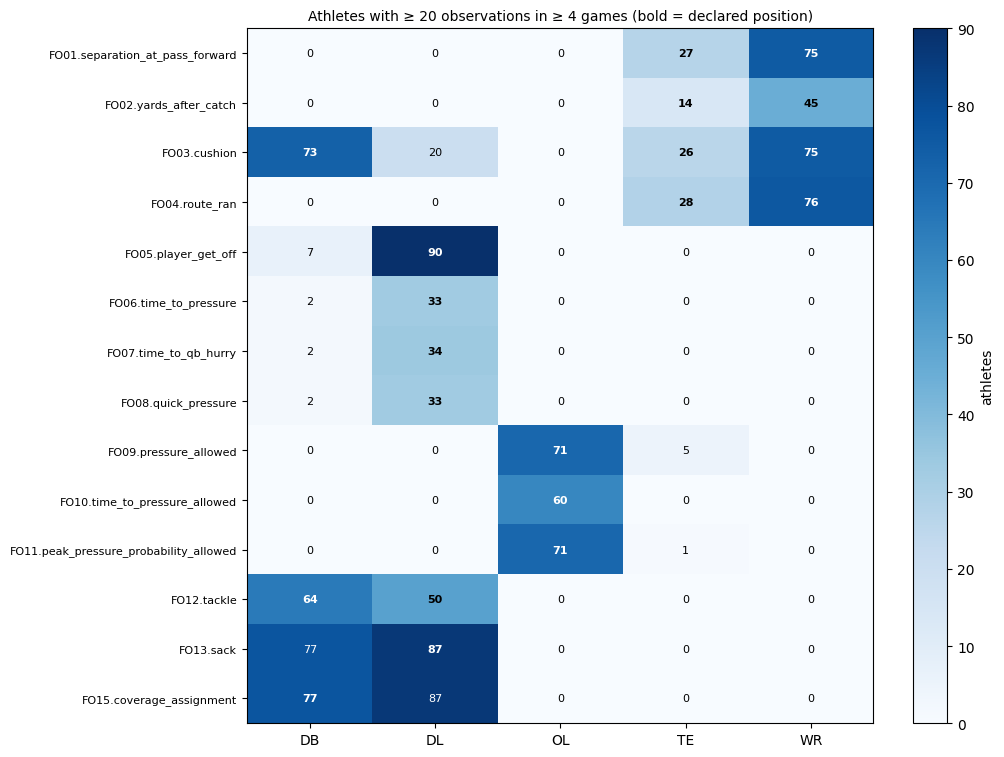

In [5]:
with pl.Config(tbl_rows=-1, tbl_width_chars=260, float_precision=3):
    display(coverage.filter(pl.col('declared_position')))
store.show(sf.fig_coverage(coverage, registry, fc), 'AM08A_01_outcome_coverage_by_position', {'coverage': coverage},
           source='football_outcome_coverage', n=f'{plays["nfl_id"].n_unique()} athletes',
           note=f'athletes with >= {fc.min_obs} observations in >= {fc.min_games} games; eligible windows of 05A')

## 3. When is a candidate recorded? (selection and label leakage)

Share of eligible player-plays of the declared positions on which the candidate is recorded, by value of its declared conditioning field. A share near 1 for one value and near 0 elsewhere means the outcome exists only in that situation: an athlete mean is then an average over a selected subset of plays. Compare with the `outcome_conditioned` declarations — **a contradiction between this table and a declaration must be corrected in `CANDIDATES` (and `EXPERIMENT_VERSION` bumped), not ignored.**

In [6]:
with pl.Config(tbl_rows=-1, tbl_width_chars=200, float_precision=3):
    display(conditions)

outcome_id,condition_field,condition_value,n_rows,n_obs,obs_share
str,str,str,i64,i64,f64
"""FO01.separation_at_pass_forwar…","""target""","""false""",34996,29665,0.848
"""FO01.separation_at_pass_forwar…","""target""","""true""",7733,7733,1.000
"""FO01.separation_at_pass_forwar…","""target""","""‹null›""",2231,0,0.000
"""FO06.time_to_pressure""","""quick_pressure""","""‹null›""",47669,9,0.000
"""FO06.time_to_pressure""","""quick_pressure""","""false""",1890,1890,1.000
"""FO06.time_to_pressure""","""quick_pressure""","""true""",804,804,1.000
"""FO10.time_to_pressure_allowed""","""pressure_allowed""","""false""",44582,0,0.000
"""FO10.time_to_pressure_allowed""","""pressure_allowed""","""‹null›""",34120,0,0.000
"""FO10.time_to_pressure_allowed""","""pressure_allowed""","""true""",4104,4101,0.999


## 4. Reliability feasibility

Athlete mean in odd versus even games (chronological rank of the athlete's own observed games), centred within position; Spearman–Brown; athlete bootstrap. One split, descriptive: a screen for *whether a reliability study is possible*, not a frozen reliability. Rates of rare events and outcome-conditioned means are shown but their reading is limited by section 3.

In [7]:
with pl.Config(fmt_str_lengths=120, tbl_rows=-1, tbl_width_chars=220, float_precision=3):
    display(reliability)

outcome_id,n_athletes_both_halves,n_positions,r_half,rel_sb,rel_lo,rel_hi,note
str,i64,i64,f64,f64,f64,f64,str
"""FO01.separation_at_pass_forward""",100,2,0.590,0.742,0.516,0.870,""""""
"""FO02.yards_after_catch""",62,2,0.517,0.682,0.365,0.827,""""""
"""FO05.player_get_off""",88,1,0.809,0.895,0.831,0.940,""""""
"""FO06.time_to_pressure""",36,1,0.421,0.593,0.294,0.775,""""""
"""FO07.time_to_qb_hurry""",36,1,0.435,0.606,0.280,0.797,""""""
"""FO08.quick_pressure""",36,1,0.267,0.422,-0.147,0.696,""""""
"""FO09.pressure_allowed""",71,1,0.298,0.459,0.113,0.687,""""""
"""FO10.time_to_pressure_allowed""",61,1,0.506,0.672,0.418,0.804,""""""
"""FO11.peak_pressure_probability_allowed""",72,1,0.616,0.763,0.622,0.867,""""""


## 5. Tracking event inventory

Which events are tagged in the tracking frames (anchors available for any future event-relative measure). One column scan of `silver.game_tracking`; skipped in smoke mode. If the column is absent the table says so.

In [8]:
events = None
if AUDIT_TRACKING_EVENTS and not controls.smoke:
    t0 = time.perf_counter()
    print('scanning the event column of silver.game_tracking …')
    events = store.build('08a_tracking_events', [sf.EVENTS],
                         lambda: {sf.EVENTS.name: sf.tracking_event_audit(refs.scan('silver', 'game_tracking'))},
                         params={'experiment_version': EXPERIMENT_VERSION}, files=refs.files('silver', 'game_tracking'))[sf.EVENTS.name]
    print(f'done ({time.perf_counter() - t0:.0f} s)')
    with pl.Config(tbl_rows=-1, fmt_str_lengths=80):
        display(events)
else:
    print('tracking event inventory skipped (smoke mode or AUDIT_TRACKING_EVENTS = False)')

16:43:25 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a_tracking_events] computing (never run)


scanning the event column of silver.game_tracking …


16:43:26 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a_tracking_events] tracking_event_inventory: 49 rows → warehouse/gold/advanced_movement/scouting_v1/tracking_event_inventory.parquet


done (1 s)


event,n_frames,n_games
str,i64,i64
"""‹null›""",21153553,1001
"""ball_snap""",314278,1001
"""pass_forward""",187479,1001
"""first_contact""",184368,1001
"""tackle""",184269,1001
"""pass_arrived""",141322,1000
"""pass_outcome_caught""",113171,1000
"""handoff""",92594,986
"""pass_outcome_incomplete""",64869,998


## 6. Feasibility registry, gate 08A, reading

Status by an ordered rule: missing field → needs a pairing of athletes → context label → career total → vendor model output → unresolved definition → coverage counts → split-half support counts → recorded only on success (`observable_conditional`) → `observable`. `defensible` additionally asks for a split-half at or above the reference line with a positive lower bound. The gate passes when the registry is complete; `branch = stop_branch` ends the football-outcome branch of Milestone 08.

outcome_id,positions,status,defensible,n_athletes_ge_min,n_positions_supported,median_games,opportunity_rate,n_athletes_both_halves,rel_sb,rel_lo,rel_hi,leakage_risk,definition_status,reason
str,str,str,bool,i64,i64,f64,f64,i64,f64,f64,f64,str,str,str
"""FO01.separation_at_pass_forward""","""WR · TE""","""observable""",true,102,2,17.000,0.832,100,0.742,0.516,0.870,"""medium""","""inferred_from_column_name""","""fields present; coverage and split-half support reach the stated counts"""
"""FO02.yards_after_catch""","""WR · TE""","""observable_conditional""",false,59,1,14.000,0.110,62,0.682,0.365,0.827,"""high""","""inferred_from_column_name""","""recorded only when the event it describes happened: the athlete mean is taken over a self-selected subset of plays"""
"""FO03.cushion""","""WR · TE · DB""","""context_only""",false,174,3,17.000,0.733,0,null,null,null,"""low""","""inferred_from_column_name""","""describes the situation of a play, not what the athlete achieved; usable as a conditioning label"""
"""FO04.route_ran""","""WR · TE""","""context_only""",false,104,2,17.000,0.950,0,null,null,null,"""low""","""inferred_from_column_name""","""describes the situation of a play, not what the athlete achieved; usable as a conditioning label"""
"""FO05.player_get_off""","""DL""","""blocked_definition""",false,90,1,17.000,0.663,88,0.895,0.831,0.940,"""medium""","""unresolved""","""vendor definition unresolved: the value cannot be given a football meaning"""
"""FO06.time_to_pressure""","""DL""","""insufficient_coverage""",false,33,1,8.500,0.054,36,0.593,0.294,0.775,"""high""","""inferred_from_column_name""","""33 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20"""
"""FO07.time_to_qb_hurry""","""DL""","""insufficient_coverage""",false,34,1,9.000,0.055,36,0.606,0.280,0.797,"""high""","""inferred_from_column_name""","""34 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20"""
"""FO08.quick_pressure""","""DL""","""insufficient_coverage""",false,33,1,8.500,0.053,36,0.422,-0.147,0.696,"""medium""","""inferred_from_column_name""","""33 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20"""
"""FO09.pressure_allowed""","""OL""","""observable""",false,71,1,14.000,0.588,71,0.459,0.113,0.687,"""medium""","""inferred_from_column_name""","""fields present; coverage and split-half support reach the stated counts"""


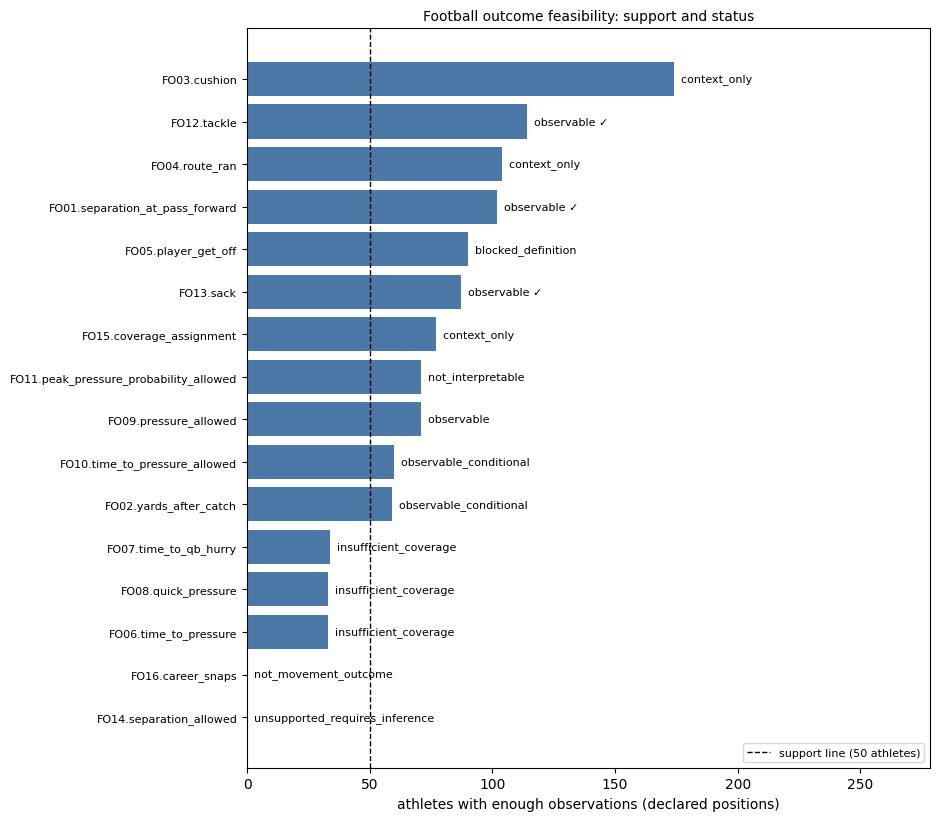

### 08A — football outcome feasibility

Gate: **PASS** · branch: **continue** · 16 candidates · blocked_definition: 1 · context_only: 3 · insufficient_coverage: 3 · not_interpretable: 1 · not_movement_outcome: 1 · observable: 4 · observable_conditional: 2 · unsupported_requires_inference: 1

| Candidate | Positions | Status | Athletes ≥ min | Split-half [95 %] | Reason |
|---|---|---|---|---|---|
| `FO01.separation_at_pass_forward` | WR · TE | observable | 102 | 0.74 [0.52, 0.87] | fields present; coverage and split-half support reach the stated counts |
| `FO02.yards_after_catch` | WR · TE | observable_conditional | 59 | 0.68 [0.36, 0.83] | recorded only when the event it describes happened: the athlete mean is taken over a self-selected subset of plays |
| `FO03.cushion` | WR · TE · DB | context_only | 174 | — | describes the situation of a play, not what the athlete achieved; usable as a conditioning label |
| `FO04.route_ran` | WR · TE | context_only | 104 | — | describes the situation of a play, not what the athlete achieved; usable as a conditioning label |
| `FO05.player_get_off` | DL | blocked_definition | 90 | 0.89 [0.83, 0.94] | vendor definition unresolved: the value cannot be given a football meaning |
| `FO06.time_to_pressure` | DL | insufficient_coverage | 33 | 0.59 [0.29, 0.77] | 33 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20 |
| `FO07.time_to_qb_hurry` | DL | insufficient_coverage | 34 | 0.61 [0.28, 0.80] | 34 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20 |
| `FO08.quick_pressure` | DL | insufficient_coverage | 33 | 0.42 [-0.15, 0.70] | 33 athletes with ≥ 20 observations in ≥ 4 games (needed 50); 1 declared position(s) reach 20 |
| `FO09.pressure_allowed` | OL | observable | 71 | 0.46 [0.11, 0.69] | fields present; coverage and split-half support reach the stated counts |
| `FO10.time_to_pressure_allowed` | OL | observable_conditional | 60 | 0.67 [0.42, 0.80] | recorded only when the event it describes happened: the athlete mean is taken over a self-selected subset of plays |
| `FO11.peak_pressure_probability_allowed` | OL | not_interpretable | 71 | 0.76 [0.62, 0.87] | output of an undocumented vendor model |
| `FO12.tackle` | DB · DL | observable | 114 | 0.61 [0.43, 0.73] | fields present; coverage and split-half support reach the stated counts |
| `FO13.sack` | DL | observable | 87 | 0.64 [0.44, 0.78] | fields present; coverage and split-half support reach the stated counts |
| `FO14.separation_allowed` | DB | unsupported_requires_inference | 0 | — | needs a pairing of athletes that no field records; pairing them by proximity would manufacture the label |
| `FO15.coverage_assignment` | DB | context_only | 77 | — | describes the situation of a play, not what the athlete achieved; usable as a conditioning label |
| `FO16.career_snaps` | DB · DL · OL · TE · WR | not_movement_outcome | 0 | — | athlete-level career total: no movement content, exposure censored by draft cohort |

Support counts: ≥ 20 observations in ≥ 4 games per athlete, ≥ 50 athletes (≥ 20 in a declared position), ≥ 30 athletes with both game halves; split-half reference line 0.50. All are heuristics declared before running.

Defensible for a later, separately designed analysis: `FO01.separation_at_pass_forward`, `FO12.tackle`, `FO13.sack`. This is an observability statement: no association with any Combine measure has been looked at.

Limits: vendor definitions are inferred from column names (no data dictionary in the repository); a null is never read as zero; assignment, opponent and scheme are unobserved; the split-half is a feasibility screen on one odd / even-game split, not a frozen reliability.

gate 08A: PASS · branch: continue · defensible: ['FO01.separation_at_pass_forward', 'FO12.tackle', 'FO13.sack']


In [9]:
GATE_08A = sf.gate_08a(registry)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1, tbl_width_chars=300, float_precision=3):
    display(registry.select('outcome_id', 'positions', 'status', 'defensible', 'n_athletes_ge_min', 'n_positions_supported', 'median_games',
                            'opportunity_rate', 'n_athletes_both_halves', 'rel_sb', 'rel_lo', 'rel_hi', 'leakage_risk', 'definition_status', 'reason'))
store.show(sf.fig_status(registry, fc), 'AM08A_02_outcome_feasibility_status', {'registry': registry},
           source='football_outcome_feasibility_registry', n=f'{registry.height} candidates',
           note='status by the ordered rule of scouting_feasibility.status_of; tick = defensible')

text = sf.conclusions_markdown(registry, GATE_08A, fc)
display(Markdown(text))
if controls.save_tables:
    (store.tables_dir / 'football_outcome_feasibility_conclusions.md').write_text(text, encoding='utf-8')
    store.write_json('football_outcome_feasibility_manifest', {
        'notebook': '08a_football_outcome_feasibility.ipynb', 'params': PARAMS, 'gate_08a': GATE_08A, 'seed': controls.seed,
        'frozen_nfl_registry': registry_doc.get('version_hash'), 'n_player_plays': plays.height, 'n_athletes': plays['nfl_id'].n_unique(),
        'tracking_events_audited': events is not None, 'source_tables': {k: len(v) for k, v in SCHEMAS.items()}, 'finished_at': utc_now()})
assert GATE_08A['gate'] == 'PASS', f'gate 08A failed — the registry is incomplete: {GATE_08A}'
print(f"gate 08A: {GATE_08A['gate']} · branch: {GATE_08A['branch']} · defensible: {GATE_08A['defensible'] or 'none'}")

### What to send back

The validation table, `football_field_audit` (with the example values of the flags), the `DECLARED` rows of `football_outcome_coverage`, `football_outcome_conditions`, `football_outcome_split_half`, the registry table, the gate line, figures `AM08A_01` / `AM08A_02`, and any traceback.

**Next.** `branch = stop_branch` → 08B–08D use the Milestone 05 movement targets and descriptive Combine evidence only. `branch = continue` → the defensible outcomes are *candidates for a separately designed, pre-registered analysis*; nothing in 08A relates them to a Combine measure.